<a href="https://colab.research.google.com/github/SrishanthGorla/SERAI/blob/main/Data_Anonymization_Simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

np.random.seed(42)

n = 200

original = pd.DataFrame({
    "record_id": range(1, n + 1),
    "name": [f"Person_{i:03d}" for i in range(1, n + 1)],
    "email": [f"person{i:03d}@example.com" for i in range(1, n + 1)],
    "age": np.random.randint(18, 66, n),
    "city": np.random.choice(
        ["Warangal", "Hyderabad", "Chennai", "Bengaluru"], n
    ),
    "occupation": np.random.choice(
        ["Student", "Employee", "Business", "Other"], n
    ),
    "salary": np.random.randint(15000, 100001, n),
    "medical_condition": np.random.choice(
        ["Yes", "No"], n, p=[0.35, 0.65]
    )
})

# Add a few missing values for the experiment
original.loc[[5, 20, 55], "salary"] = np.nan

print("Original dataset created!")
print("Shape:", original.shape)
display(original.head(10))


Original dataset created!
Shape: (200, 8)


,record_id,name,email,age,city,occupation,salary,medical_condition
0,1,Person_001,person001@example.com,56,Warangal,Business,75403.0,No
1,2,Person_002,person002@example.com,46,Bengaluru,Other,44124.0,Yes
2,3,Person_003,person003@example.com,32,Warangal,Student,58919.0,Yes
3,4,Person_004,person004@example.com,60,Hyderabad,Other,50247.0,No
4,5,Person_005,person005@example.com,25,Warangal,Student,77752.0,No
5,6,Person_006,person006@example.com,38,Hyderabad,Other,NaN,No
6,7,Person_007,person007@example.com,56,Bengaluru,Other,74101.0,Yes
7,8,Person_008,person008@example.com,36,Bengaluru,Employee,41646.0,No
8,9,Person_009,person009@example.com,40,Hyderabad,Student,38049.0,No
9,10,Person_010,person010@example.com,28,Chennai,Employee,94605.0,No


In [2]:

pseudonymized = original.copy()

# Create artificial identifiers
pseudonymized["person_token"] = [
    f"USER_{i:04d}" for i in range(1, len(original) + 1)
]

# Keep the re-identification mapping separate
mapping_table = original[["record_id", "name", "email"]].copy()
mapping_table["person_token"] = pseudonymized["person_token"]

# Remove direct identifiers from the working dataset
pseudonymized = pseudonymized.drop(
    columns=["record_id", "name", "email"]
)

print("Pseudonymization completed!")
display(pseudonymized.head(10))

print("Separate mapping table (restricted access):")
display(mapping_table.head())


Pseudonymization completed!


,age,city,occupation,salary,medical_condition,person_token
0,56,Warangal,Business,75403.0,No,USER_0001
1,46,Bengaluru,Other,44124.0,Yes,USER_0002
2,32,Warangal,Student,58919.0,Yes,USER_0003
3,60,Hyderabad,Other,50247.0,No,USER_0004
4,25,Warangal,Student,77752.0,No,USER_0005
5,38,Hyderabad,Other,NaN,No,USER_0006
6,56,Bengaluru,Other,74101.0,Yes,USER_0007
7,36,Bengaluru,Employee,41646.0,No,USER_0008
8,40,Hyderabad,Student,38049.0,No,USER_0009
9,28,Chennai,Employee,94605.0,No,USER_0010


Separate mapping table (restricted access):


,record_id,name,email,person_token
0,1,Person_001,person001@example.com,USER_0001
1,2,Person_002,person002@example.com,USER_0002
2,3,Person_003,person003@example.com,USER_0003
3,4,Person_004,person004@example.com,USER_0004
4,5,Person_005,person005@example.com,USER_0005


In [3]:

anonymized = original.drop(
    columns=["record_id", "name", "email"]
).copy()

# Generalize exact age into age groups
anonymized["age_group"] = pd.cut(
    anonymized["age"],
    bins=[17, 29, 39, 49, 59, 100],
    labels=["18-29", "30-39", "40-49", "50-59", "60+"]
)

# Generalize salary into broad bands
anonymized["salary_band"] = pd.cut(
    anonymized["salary"],
    bins=[0, 30000, 50000, 75000, float("inf")],
    labels=["Up to 30k", "30k-50k", "50k-75k", "Above 75k"],
    include_lowest=True
)

# Remove the original precise values
anonymized = anonymized.drop(columns=["age", "salary"])

print("Anonymization transformation completed!")
display(anonymized.head(10))

print("Remaining direct identifiers:")
print([
    col for col in ["record_id", "name", "email"]
    if col in anonymized.columns
])


Anonymization transformation completed!


,city,occupation,medical_condition,age_group,salary_band
0,Warangal,Business,No,50-59,Above 75k
1,Bengaluru,Other,Yes,40-49,30k-50k
2,Warangal,Student,Yes,30-39,50k-75k
3,Hyderabad,Other,No,60+,50k-75k
4,Warangal,Student,No,18-29,Above 75k
5,Hyderabad,Other,No,30-39,NaN
6,Bengaluru,Other,Yes,50-59,50k-75k
7,Bengaluru,Employee,No,30-39,30k-50k
8,Hyderabad,Student,No,40-49,30k-50k
9,Chennai,Employee,No,18-29,Above 75k


Remaining direct identifiers:
[]


In [4]:

def dataset_summary(df, name):
    return {
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing values": int(df.isnull().sum().sum()),
        "Direct identifiers present": any(
            c in df.columns for c in ["record_id", "name", "email"]
        )
    }

comparison = pd.DataFrame([
    dataset_summary(original, "Original"),
    dataset_summary(pseudonymized, "Pseudonymized"),
    dataset_summary(anonymized, "Anonymized")
])

display(comparison)


,Dataset,Rows,Columns,Missing values,Direct identifiers present
0,Original,200,8,3,True
1,Pseudonymized,200,6,3,False
2,Anonymized,200,5,3,False


In [5]:

def evaluate_model(df, feature_columns, target="medical_condition"):
    X = df[feature_columns].copy()
    y = df[target].copy()

    # Use identical train/test row indices for a fair comparison
    train_idx, test_idx = train_test_split(
        np.arange(len(df)),
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    numerical = X.select_dtypes(
        include=["number"]
    ).columns.tolist()

    categorical = [
        c for c in feature_columns if c not in numerical
    ]

    transformers = []

    if numerical:
        transformers.append((
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numerical
        ))

    if categorical:
        transformers.append((
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical
        ))

    preprocessor = ColumnTransformer(transformers)

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    return {
        "Accuracy": accuracy_score(y_test, predictions),
        "F1-score": f1_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        )
    }


original_metrics = evaluate_model(
    original,
    ["age", "city", "occupation", "salary"]
)

anonymized_metrics = evaluate_model(
    anonymized,
    ["age_group", "city", "occupation", "salary_band"]
)

model_comparison = pd.DataFrame([
    {"Dataset": "Original", **original_metrics},
    {"Dataset": "Anonymized", **anonymized_metrics}
])

display(model_comparison.round(3))


,Dataset,Accuracy,F1-score
0,Original,0.525,0.095
1,Anonymized,0.525,0.095


In [6]:

before_after = pd.DataFrame([
    {
        "Property": "Direct identifiers",
        "Original": "Name, email, record ID",
        "Pseudonymized": "Replaced with artificial token",
        "Anonymized": "Removed"
    },
    {
        "Property": "Age",
        "Original": "Exact age",
        "Pseudonymized": "Exact age",
        "Anonymized": "Age group"
    },
    {
        "Property": "Salary",
        "Original": "Exact salary",
        "Pseudonymized": "Exact salary",
        "Anonymized": "Salary band"
    },
    {
        "Property": "Mapping table",
        "Original": "Not required",
        "Pseudonymized": "Required for re-linking",
        "Anonymized": "Not retained in the released dataset"
    },
    {
        "Property": "Re-identification risk",
        "Original": "High",
        "Pseudonymized": "Remains if mapping is exposed",
        "Anonymized": "Reduced, not eliminated"
    }
])

display(before_after)


,Property,Original,Pseudonymized,Anonymized
0,Direct identifiers,"Name, email, record ID",Replaced with artificial token,Removed
1,Age,Exact age,Exact age,Age group
2,Salary,Exact salary,Exact salary,Salary band
3,Mapping table,Not required,Required for re-linking,Not retained in the released dataset
4,Re-identification risk,High,Remains if mapping is exposed,"Reduced, not eliminated"


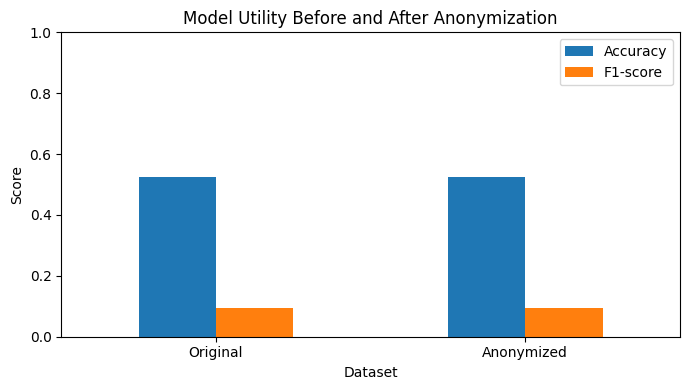

In [7]:

model_comparison.set_index("Dataset")[
    ["Accuracy", "F1-score"]
].plot(kind="bar", figsize=(7, 4))

plt.title("Model Utility Before and After Anonymization")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [8]:

original.to_csv("original_dataset.csv", index=False)
pseudonymized.to_csv("pseudonymized_dataset.csv", index=False)
anonymized.to_csv("anonymized_dataset.csv", index=False)

comparison.to_csv("dataset_comparison.csv", index=False)
model_comparison.to_csv("model_utility_comparison.csv", index=False)
before_after.to_csv("before_after_comparison.csv", index=False)

print("All assignment files saved successfully!")


All assignment files saved successfully!
